In [1]:
# ============================================================
#  Project 7: NLP — Sentiment Analysis on Amazon Reviews
# ============================================================

# Step 1: Load & Explore Data
import pandas as pd

# Load dataset
data = pd.read_csv("C:/Users/krishna/Downloads/moviereviews.tsv", sep="\t")
# Preview
print(data.head())
print(data['label'].value_counts())


  label                                             review
0   neg  how do films like mouse hunt get into theatres...
1   neg  some talented actresses are blessed with a dem...
2   pos  this has been an extraordinary year for austra...
3   pos  according to hollywood movies made in last few...
4   neg  my first press screening of 1998 and already i...
label
neg    1000
pos    1000
Name: count, dtype: int64


In [2]:
# Text Cleaning
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Ensure resources are available
nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    # Convert to string and handle NaN
    text = str(text)
    # Lowercase
    text = text.lower()
    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    # Keep only letters
    text = re.sub(r'[^a-zA-Z]', ' ', text)
    # Tokenize
    tokens = text.split()
    # Remove stopwords and lemmatize
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words]
    return " ".join(tokens)

# Drop rows where 'review' is missing
data = data.dropna(subset=['review'])

# Apply cleaning
data['clean_review'] = data['review'].astype(str).apply(clean_text)


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\krishna\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\krishna\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [3]:
# Step 2: Feature Engineering
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF vectorization
tfidf = TfidfVectorizer(max_features=5000)
data = data.rename(columns={'label': 'sentiment'})
X = tfidf.fit_transform(data['clean_review'])
y = data['sentiment']
print(X.shape, y.shape)


(1965, 5000) (1965,)


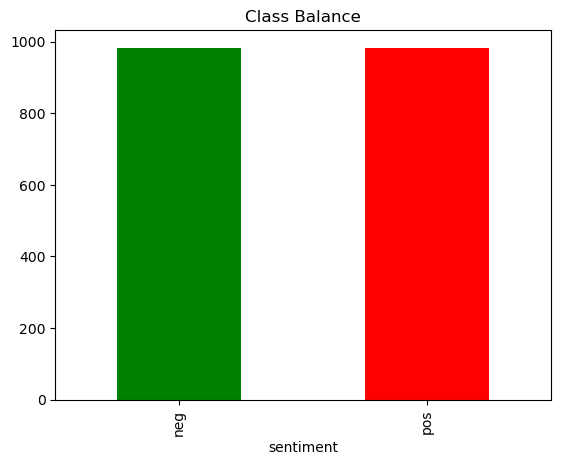

In [4]:
# Step 3: Exploratory Data Analysis (EDA)
# Class Balance
import matplotlib.pyplot as plt

data['sentiment'].value_counts().plot(kind='bar', color=['green','red'])
plt.title("Class Balance")
plt.show()


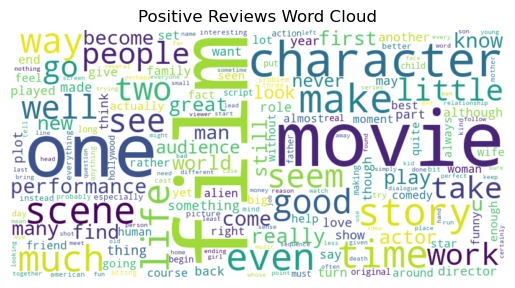

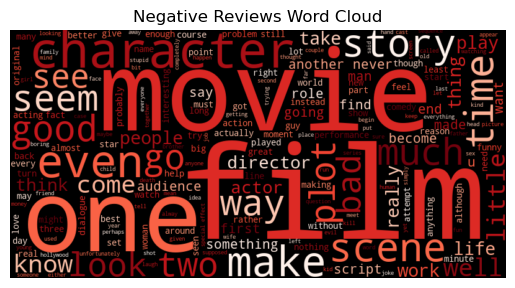

In [5]:
# Word Clouds
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Positive reviews
positive_text = " ".join(data[data['sentiment']=='pos']['clean_review'])

# Negative reviews
negative_text = " ".join(data[data['sentiment']=='neg']['clean_review'])

wordcloud_pos = WordCloud(width=800, height=400, background_color='white').generate(positive_text)
plt.imshow(wordcloud_pos, interpolation='bilinear')
plt.axis("off")
plt.title("Positive Reviews Word Cloud")
plt.show()

wordcloud_neg = WordCloud(width=800, height=400, background_color='black', colormap='Reds').generate(negative_text)
plt.imshow(wordcloud_neg, interpolation='bilinear')
plt.axis("off")
plt.title("Negative Reviews Word Cloud")
plt.show()


In [6]:
# Step 4: Model Building
# Train/Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [7]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print("Logistic Regression Results:")
print(classification_report(y_test, y_pred_lr))


Logistic Regression Results:
              precision    recall  f1-score   support

         neg       0.83      0.82      0.83       202
         pos       0.81      0.82      0.82       191

    accuracy                           0.82       393
   macro avg       0.82      0.82      0.82       393
weighted avg       0.82      0.82      0.82       393



In [8]:
# Naive Bayes
from sklearn.naive_bayes import MultinomialNB

nb = MultinomialNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

print("Naive Bayes Results:")
print(classification_report(y_test, y_pred_nb))


Naive Bayes Results:
              precision    recall  f1-score   support

         neg       0.80      0.87      0.83       202
         pos       0.84      0.76      0.80       191

    accuracy                           0.82       393
   macro avg       0.82      0.82      0.82       393
weighted avg       0.82      0.82      0.82       393

